# Crowdcast: accuracy diagnosis (before improving anything)

Friends testing the live app found everyday photos overcounted. For example, a group of **8 people came out
as 12–18**. Before changing the model, this notebook measures the **current** models honestly:

1. **Train vs validation vs test error** for both models. Is the model overfitting (train much better than
   validation/test), underfitting (all bad), or fine on its own kind of data?
2. **Learning curves** from the training logs.
3. **Error by crowd size**, and whether the model **over- or undercounts** (bias).
4. **A real-world small-group test set**: everyday photos with 1–20 clearly visible people from **COCO val2017**
   (exact person labels), plus the sparsest ShanghaiTech B photos. These are the "before" numbers that any fix
   must beat.

Nothing is retrained here. The models are exactly the ones the live app uses. Predictions are saved to
`data/cache/diagnosis_predictions.csv` as they are made, so an interrupted run resumes where it stopped.

## 1. Setup

In [1]:
import os, sys, json, re, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"   # ~60x faster full-image inference on this CPU (see notebook 01)

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from PIL import Image

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "app"))
import crowd_model as cm   # the exact code the app uses

ST = os.path.join(ROOT, "data", "shanghaitech", "ShanghaiTech")
COCO = os.path.join(ROOT, "data", "coco")
WEIGHTS = os.path.join(ROOT, "weights")
SEED, VAL_FRACTION = 42, 0.15   # the split used when the models were trained (notebooks 02 and 03)
pd.set_option("display.width", 160)

models = {kind: cm.load_model(kind) for kind in cm.MODELS}
print("Loaded:", ", ".join(f"{k} ({cm.MODELS[k].weights_file})" for k in models))

# Every prediction is saved to a file as soon as it is made, so an interrupted run resumes
# instead of starting over. A progress line is written every 25 photos.
PRED_FILE = os.path.join(ROOT, "data", "cache", "diagnosis_predictions.csv")
LOG_FILE = os.path.join(ROOT, "data", "cache", "diagnosis_progress.log")
os.makedirs(os.path.dirname(PRED_FILE), exist_ok=True)
saved = pd.read_csv(PRED_FILE) if os.path.exists(PRED_FILE) else pd.DataFrame(columns=["key", "pred"])
cache = dict(zip(saved["key"], saved["pred"]))
done_now = 0
print(f"{len(cache)} predictions already saved from earlier runs")

def predict(kind, path):
    global done_now
    key = f"{kind}|{os.path.relpath(path, ROOT)}"
    if key not in cache:
        img, _ = cm.prepare_image(Image.open(path))
        cache[key] = float(max(cm.predict_density(models[kind], img).sum(), 0))
        with open(PRED_FILE, "a", encoding="utf-8") as f:
            if f.tell() == 0: f.write("key,pred\n")
            f.write(f"{key},{cache[key]}\n")
        done_now += 1
        if done_now % 25 == 0:
            with open(LOG_FILE, "a", encoding="utf-8") as f:
                f.write(f"{time.strftime('%H:%M:%S')} {done_now} new predictions ({len(cache)} total)\n")
    return cache[key]

Loaded: dense (csrnet_partA_v2_best.weights.h5), street (csrnet_partB_best.weights.h5)
0 predictions already saved from earlier runs


## 2. Rebuild the exact train / validation / test splits

Same order and seed as training: images sorted by number, then a seeded shuffle, with the first 15% held
out as validation. So "train" here is exactly what each model learned from.

In [2]:
def load_part(part):
    out = {}
    for split in ["train", "test"]:
        img_dir = os.path.join(ST, f"part_{part}", f"{split}_data", "images")
        names = sorted(os.listdir(img_dir), key=lambda n: int(n.split("_")[1].split(".")[0]))
        items = []
        for n in names:
            info = sio.loadmat(os.path.join(ST, f"part_{part}", f"{split}_data", "ground-truth",
                                            "GT_" + n.replace(".jpg", ".mat")))["image_info"][0, 0][0, 0]
            items.append({"path": os.path.join(img_dir, n), "name": n, "true": float(info[1][0, 0])})
        out[split] = items
    perm = np.random.default_rng(SEED).permutation(len(out["train"]))
    n_val = int(round(VAL_FRACTION * len(out["train"])))
    out["val"] = [out["train"][i] for i in perm[:n_val]]
    out["train"] = [out["train"][i] for i in perm[n_val:]]
    return out

parts = {"A": load_part("A"), "B": load_part("B")}
for p, d in parts.items():
    print(f"Part {p}: train {len(d['train'])}, validation {len(d['val'])}, test {len(d['test'])}")

Part A: train 255, validation 45, test 182
Part B: train 340, validation 60, test 316


## 3. Train vs validation vs test

Each model counts every image in its own train, validation and test sets. Full images, the same way the app counts.

**How to read it:**
- train ≪ validation/test → **overfitting** (memorising)
- all three high → **underfitting**
- all three similar and low → the model has learned this kind of photo well. Any problem elsewhere is then
  **domain shift**: real photos that look different from the training data.

In [3]:
model_for_part = {"A": "dense", "B": "street"}
rows, preds = [], {}
t0 = time.time()
for p, kind in model_for_part.items():
    for split in ["train", "val", "test"]:
        items = parts[p][split]
        pr = np.array([predict(kind, it["path"]) for it in items])
        tr = np.array([it["true"] for it in items])
        preds[(p, split)] = (pr, tr)
        err = pr - tr
        rows.append({"Model": f"{cm.MODELS[kind].label} (Part {p})", "Split": split, "Images": len(items),
                     "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()),
                     "Bias": err.mean(), "Avg people": tr.mean(), "Error %": np.abs(err).mean() / tr.mean() * 100})
    print(f"Part {p} done ({(time.time() - t0) / 60:.1f} min)")
tvt = pd.DataFrame(rows)
print()
print(tvt.to_string(index=False, formatters={"MAE": "{:.1f}".format, "RMSE": "{:.1f}".format, "Bias": "{:+.1f}".format,
                                              "Avg people": "{:.0f}".format, "Error %": "{:.0f}%".format}))
print("\nBias = average (predicted - true). Positive = overcounts.")

Part A done (32.5 min)


Part B done (99.5 min)



                Model Split  Images   MAE  RMSE  Bias Avg people Error %
 Dense crowd (Part A) train     255  61.2  95.3  -6.9        538     11%
 Dense crowd (Part A)   val      45 106.3 185.6 -67.9        561     19%
 Dense crowd (Part A)  test     182  79.6 112.2  +3.0        433     18%
Street scene (Part B) train     340  12.6  18.9  +4.0        123     10%
Street scene (Part B)   val      60  12.8  19.8  +4.5        120     11%
Street scene (Part B)  test     316  13.4  20.6  +4.6        124     11%

Bias = average (predicted - true). Positive = overcounts.


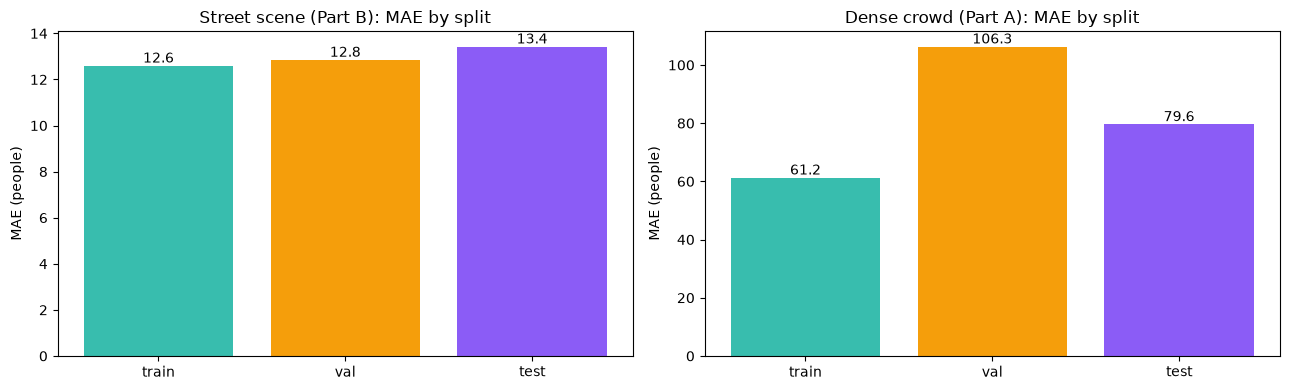

Part B: validation/train MAE ratio 1.02 -> healthy: train and validation are close
Part A: validation/train MAE ratio 1.74 -> some overfitting: validation error is clearly higher than train


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, p in zip(axes, ["B", "A"]):
    d = tvt[tvt["Model"].str.contains(f"Part {p}")]
    ax.bar(d["Split"], d["MAE"], color=["#38bdae", "#f59e0b", "#8b5cf6"])
    for x, v in zip(d["Split"], d["MAE"]): ax.text(x, v, f"{v:.1f}", ha="center", va="bottom")
    ax.set(title=f"{d['Model'].iloc[0]}: MAE by split", ylabel="MAE (people)")
plt.tight_layout(); plt.show()

for p in ["B", "A"]:
    d = tvt[tvt["Model"].str.contains(f"Part {p}")].set_index("Split")
    gap = d.loc["val", "MAE"] / d.loc["train", "MAE"]
    verdict = ("healthy: train and validation are close" if gap < 1.3 else
               "some overfitting: validation error is clearly higher than train" if gap < 2 else
               "strong overfitting: validation error is more than double train")
    print(f"Part {p}: validation/train MAE ratio {gap:.2f} -> {verdict}")

## 4. Learning curves (from the training logs)

Per-epoch error on a fixed subset of training images vs the validation images, as recorded during training.

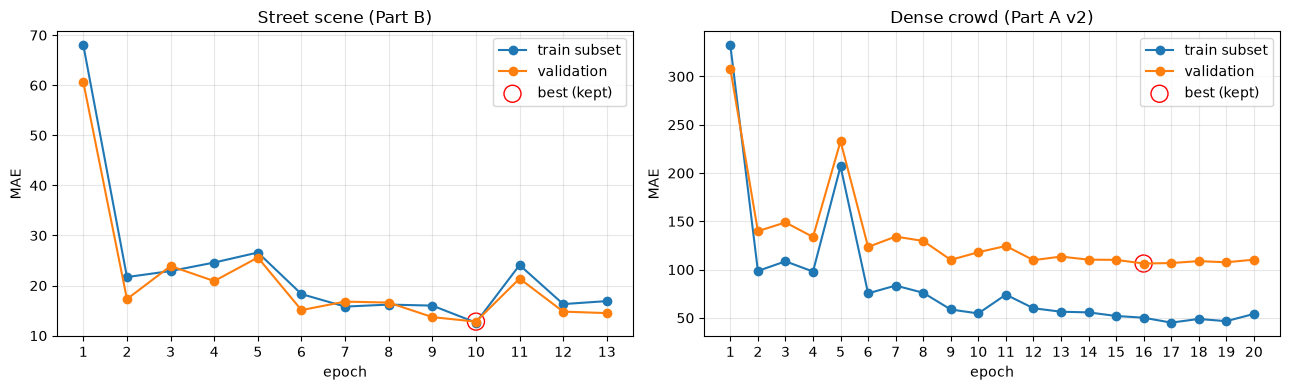

In [5]:
def parse_log(path):
    ep, tr, va = [], [], []
    epoch = None
    for line in open(path, encoding="utf-8"):
        m = re.search(r"Epoch (\d+)/", line)
        if m: epoch = int(m.group(1))
        m = re.search(r"train MAE ([0-9.]+) \| val MAE ([0-9.]+)", line)
        if m: ep.append(epoch); tr.append(float(m.group(1))); va.append(float(m.group(2)))
    return ep, tr, va

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, log) in zip(axes, [("Street scene (Part B)", "csrnet_partB_train_log.txt"),
                                   ("Dense crowd (Part A v2)", "csrnet_partA_v2_train_log.txt")]):
    ep, tr, va = parse_log(os.path.join(WEIGHTS, log))
    ax.plot(ep, tr, "o-", label="train subset"); ax.plot(ep, va, "o-", label="validation")
    b = int(np.argmin(va)); ax.scatter([ep[b]], [va[b]], s=150, facecolors="none", edgecolors="red", label="best (kept)")
    ax.set(title=title, xlabel="epoch", ylabel="MAE", xticks=ep); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 5. Error by crowd size (test sets)

In [6]:
for p in ["B", "A"]:
    pr, tr = preds[(p, "test")]
    edges = np.quantile(tr, [0, .25, .5, .75, 1])
    which = np.clip(np.digitize(tr, edges[1:-1]), 0, 3)
    t = pd.DataFrame({"people": [f"{edges[i]:.0f}-{edges[i+1]:.0f}" for i in range(4)],
                      "images": [int((which == i).sum()) for i in range(4)],
                      "MAE": [np.abs(pr - tr)[which == i].mean() for i in range(4)],
                      "Bias": [(pr - tr)[which == i].mean() for i in range(4)],
                      "Error %": [(np.abs(pr - tr) / tr)[which == i].mean() * 100 for i in range(4)]})
    print(f"Part {p} test ({cm.MODELS[model_for_part[p]].label} model):")
    print(t.to_string(index=False, formatters={"MAE": "{:.1f}".format, "Bias": "{:+.1f}".format, "Error %": "{:.0f}%".format}))
    print()

Part B test (Street scene model):
 people  images  MAE Bias Error %
   9-55      79  3.4 +0.9      9%
  55-93      78  8.8 +4.4     12%
 93-167      79 16.6 +5.4     13%
167-539      80 24.6 +7.5     10%

Part A test (Dense crowd model):
  people  images   MAE  Bias Error %
  66-211      45  38.3 +15.1     28%
 211-308      46  61.1  +8.6     24%
 308-501      45  89.6 +29.2     23%
501-2256      46 128.6 -40.1     14%



## 6. Real-world small groups: the "before" numbers

**COCO val2017** has everyday photos (group shots, teams, streets, indoors) with every person labelled. To make
the true count unambiguous, we kept only photos where:
- no region is marked "crowd" (those have no exact count)
- **every** person is at least 3% of the photo's height, so clearly visible

That gives 225 photos, 75 each with 1–5, 6–10 and 11–20 people. Each group is split into 25 for tuning
the coming fix (validation) and 50 for the final test. COCO has almost no fully labelled photos with 21+ people,
so the **sparsest ShanghaiTech B test photos (≤ 30 people)** are added as a second set.

The app's default is the **Street scene** model; the Dense crowd model is shown too.

**Metrics a user cares about:**
- **MAE:** people off on average
- **Exact:** the rounded count equals the true count
- **Within ±1:** off by at most one person
- **Error %:** average error relative to the true count
- **Bias:** average (predicted − true); positive means overcounting

In [7]:
coco = pd.read_csv(os.path.join(COCO, "small_groups.csv"))
for kind in ["street", "dense"]:
    coco[f"pred_{kind}"] = [predict(kind, os.path.join(COCO, "images", f)) for f in coco["file_name"]]

sparse_b = [it for it in parts["B"]["test"] if it["true"] <= 30]
sb = pd.DataFrame({"file_name": [it["name"] for it in sparse_b], "true_count": [it["true"] for it in sparse_b]})
for kind in ["street", "dense"]:
    sb[f"pred_{kind}"] = [predict(kind, it["path"]) for it in sparse_b]

def summary(d, col):
    err = d[col] - d["true_count"]
    return {"Images": len(d), "MAE": err.abs().mean(), "Exact": (d[col].round() == d["true_count"]).mean(),
            "Within ±1": (err.abs() <= 1).mean(), "Error %": (err.abs() / d["true_count"]).mean() * 100,
            "Bias": err.mean()}

rows = []
for name, d in [("COCO 1-5 people", coco[coco["bin"] == "1-5"]), ("COCO 6-10 people", coco[coco["bin"] == "6-10"]),
                ("COCO 11-20 people", coco[coco["bin"] == "11-20"]), ("COCO all (1-20)", coco),
                ("ShanghaiTech B, <=30 people", sb)]:
    for kind in ["street", "dense"]:
        rows.append({"Set": name, "Model": cm.MODELS[kind].label, **summary(d, f"pred_{kind}")})
before = pd.DataFrame(rows)
print(before.to_string(index=False, formatters={"MAE": "{:.1f}".format, "Exact": "{:.0%}".format,
                                                 "Within ±1": "{:.0%}".format, "Error %": "{:.0f}%".format, "Bias": "{:+.1f}".format}))

                        Set        Model  Images  MAE Exact Within ±1 Error %  Bias
            COCO 1-5 people Street scene      75  3.4   29%       45%    239%  +3.0
            COCO 1-5 people  Dense crowd      75 19.0   11%       20%   1255% +18.6
           COCO 6-10 people Street scene      75  7.1    9%       17%     93%  +5.6
           COCO 6-10 people  Dense crowd      75 27.1    4%       11%    353% +26.3
          COCO 11-20 people Street scene      75 11.0    4%        8%     93%  +9.5
          COCO 11-20 people  Dense crowd      75 18.4    5%        9%    156% +17.3
            COCO all (1-20) Street scene     225  7.2   14%       24%    142%  +6.0
            COCO all (1-20)  Dense crowd     225 21.5    7%       13%    588% +20.7
ShanghaiTech B, <=30 people Street scene      19  3.0   21%       26%     13%  +1.5
ShanghaiTech B, <=30 people  Dense crowd      19  9.1    0%        0%     39%  +4.2


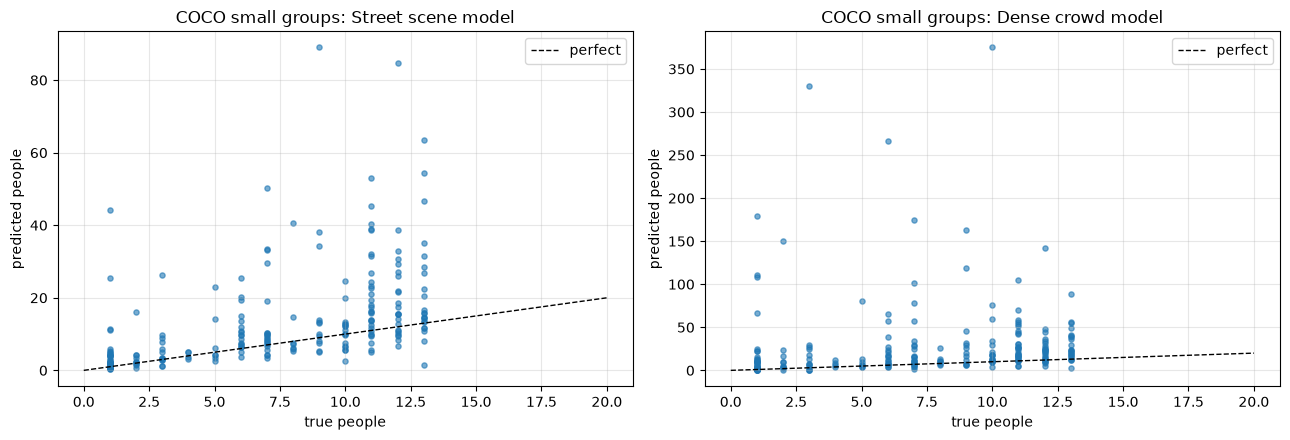

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, kind in zip(ax, ["street", "dense"]):
    a.scatter(coco["true_count"], coco[f"pred_{kind}"], s=14, alpha=.6)
    a.plot([0, 20], [0, 20], "k--", lw=1, label="perfect")
    a.set(title=f"COCO small groups: {cm.MODELS[kind].label} model", xlabel="true people", ylabel="predicted people")
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### The worst overcounts (Street scene model), with the model's heatmap

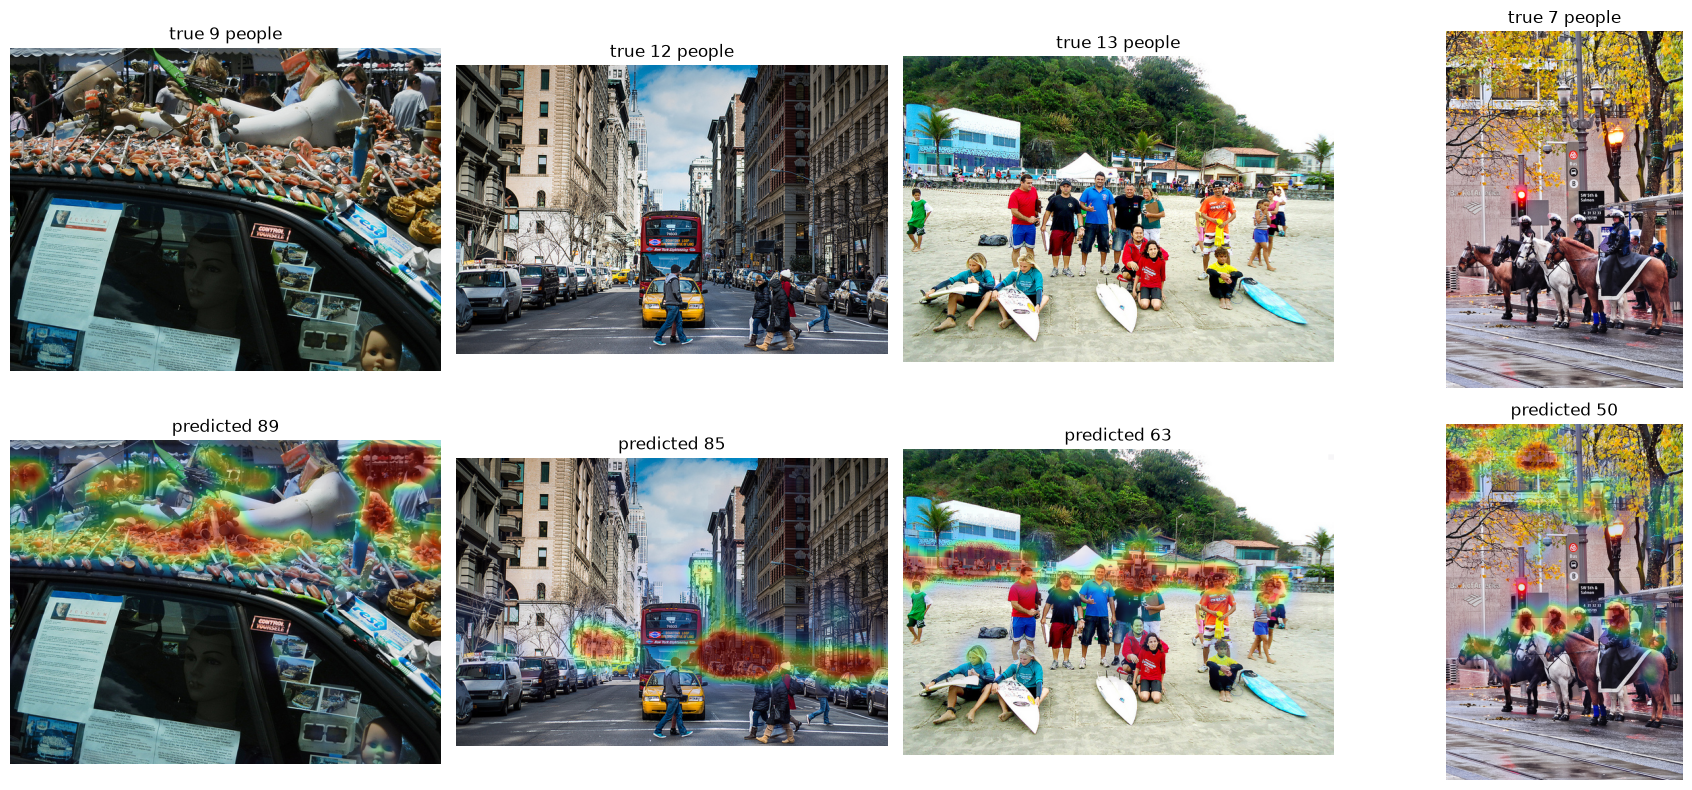

In [9]:
worst = coco.assign(err=coco["pred_street"] - coco["true_count"]).nlargest(4, "err")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for k, (_, r) in enumerate(worst.iterrows()):
    img, _ = cm.prepare_image(Image.open(os.path.join(COCO, "images", r["file_name"])))
    dmap = cm.predict_density(models["street"], img)
    axes[0, k].imshow(img); axes[0, k].set_title(f"true {r['true_count']} people")
    axes[1, k].imshow(cm.heatmap_overlay(img, dmap)); axes[1, k].set_title(f"predicted {r['pred_street']:.0f}")
    for a in axes[:, k]: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Summary of the diagnosis

Printed from the numbers above, so it always matches the run.

In [10]:
b_tvt = tvt[tvt["Model"].str.contains("Part B")].set_index("Split")["MAE"]
a_tvt = tvt[tvt["Model"].str.contains("Part A")].set_index("Split")["MAE"]
c_all = before[(before["Set"] == "COCO all (1-20)") & (before["Model"] == "Street scene")].iloc[0]
print(f"1. Street scene model on ShanghaiTech B: train {b_tvt['train']:.1f}, validation {b_tvt['val']:.1f}, test {b_tvt['test']:.1f} MAE.")
print(f"2. Dense crowd model on ShanghaiTech A: train {a_tvt['train']:.1f}, validation {a_tvt['val']:.1f}, test {a_tvt['test']:.1f} MAE.")
print(f"3. On everyday photos with 1-20 people (COCO), the Street scene model is off by {c_all['MAE']:.1f} people on average "
      f"({c_all['Error %']:.0f}% of the true count), gets the exact count {c_all['Exact']:.0%} of the time, "
      f"and its average bias is {c_all['Bias']:+.1f} people.")

1. Street scene model on ShanghaiTech B: train 12.6, validation 12.8, test 13.4 MAE.
2. Dense crowd model on ShanghaiTech A: train 61.2, validation 106.3, test 79.6 MAE.
3. On everyday photos with 1-20 people (COCO), the Street scene model is off by 7.2 people on average (142% of the true count), gets the exact count 14% of the time, and its average bias is +6.0 people.
